# Compulsory Assignement 4, Dat200
**Group4** Lasse Lindholm & Brage Bromset Bestvold

# Imports

In [ ]:
# for preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# different classifers
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier 


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# for measuring performance
from sklearn.metrics import accuracy_score


# for feature selection
from sklearn.feature_selection import SequentialFeatureSelector

# Train test split
from sklearn.model_selection import train_test_split

# Pipelin
from sklearn.pipeline      import make_pipeline

# dimension reduction
from sklearn.decomposition import PCA

# To stop warnings from
import warnings
warnings.filterwarnings("ignore", category=Warning, module="sklearn")

# Reading/Loading the data

In [2]:
train = pd.read_csv("trainCA4DAT200.csv")
test = pd.read_csv("testCA4DAT200.csv")
train.head()

,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


# Data Exploration


TypeError: The x variable is categorical, but one of ['numeric', 'datetime'] is required

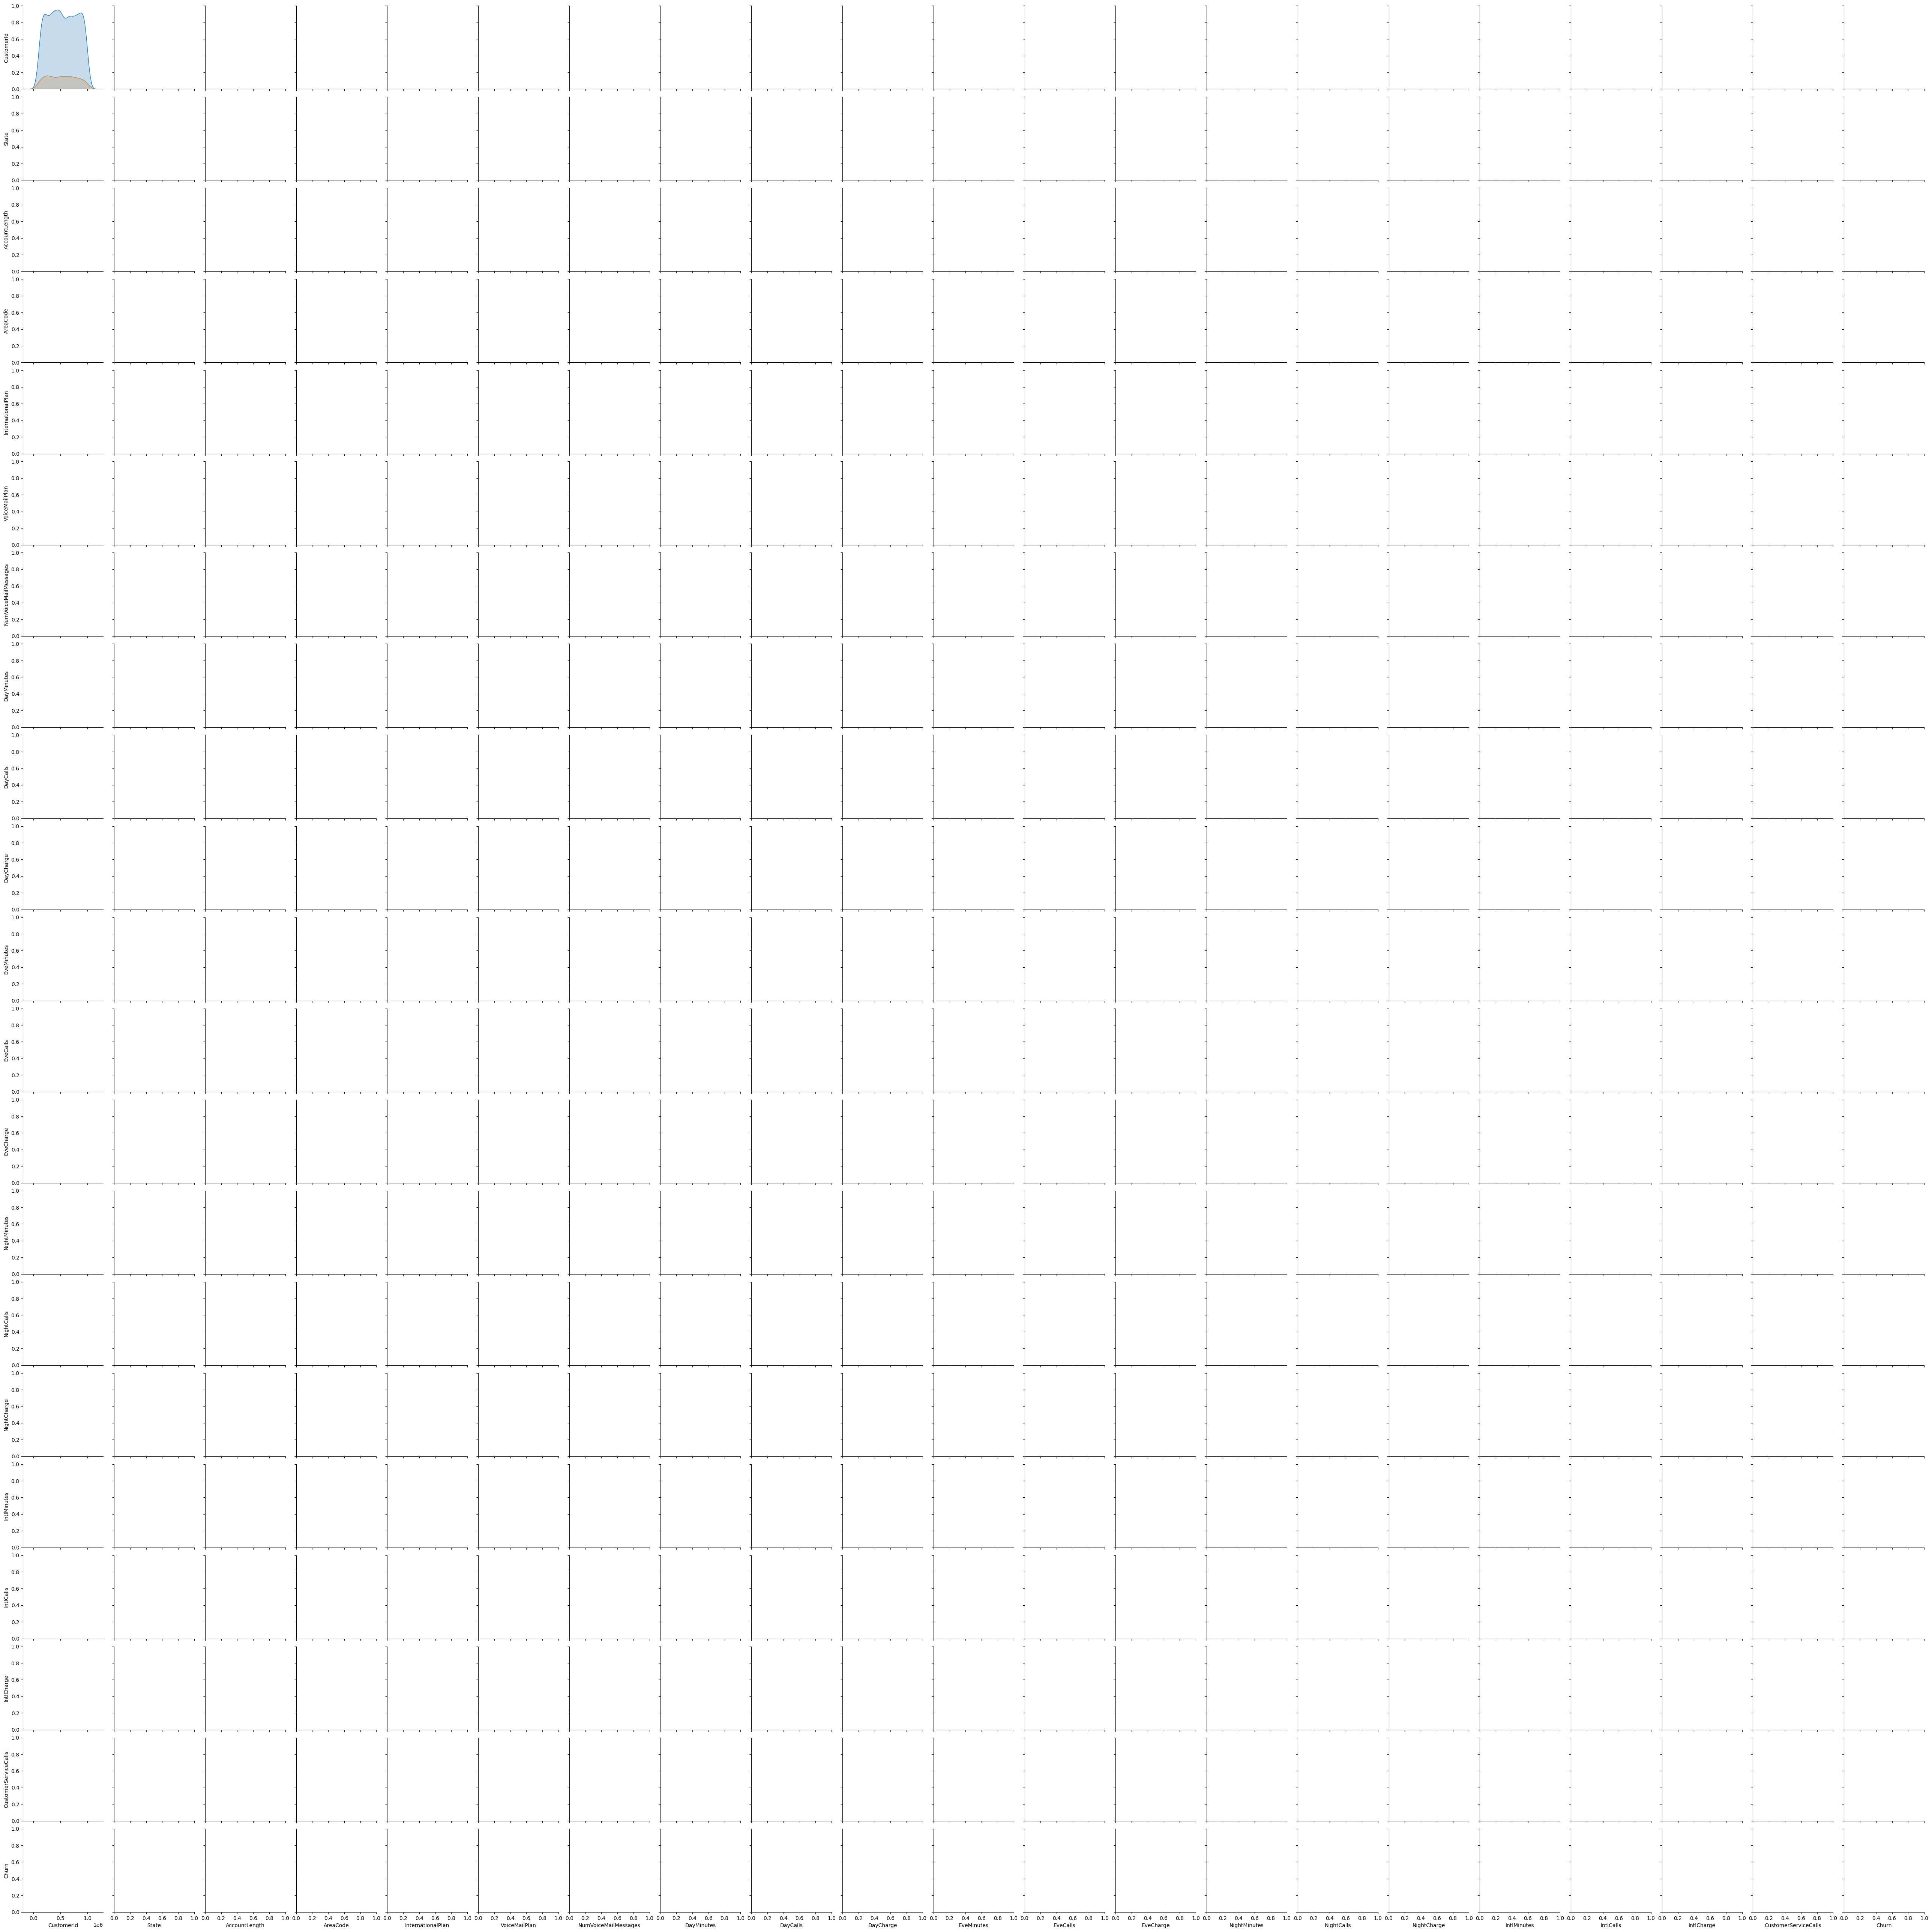

In [5]:
sns.pairplot(train, vars=train.keys(), hue="Churn")

plt.show()



# Modified correlation heatmap taken from the 04_correlationmap.ipynb example from canvas
# https://nmbu.instructure.com/courses/14056/files/folder/Lecture_12_Preprocessing?preview=2814845
def plot_correlation_heatmap(data, title):
    """
    Plot a correlation heatmap for a given dataset
    """
    df = pd.DataFrame(data, columns=data.keys())
    df['Churn'] = data.Churn
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
    plt.title(title)
    plt.show()

plt.figure(figsize=(20, 20))
plot_correlation_heatmap(train, 'Wine dataset')



fig, ax = plt.subplots(1, len(train.columns), figsize=(30, 5))
fig.suptitle("Boxplots of each column", fontsize=18)

for i, col in enumerate(train.columns):
    ax[i].boxplot(train[col])
    ax[i].set_title(col, fontsize=9)
    ax[i].set_xticks([]) 

plt.tight_layout()
plt.show()

# Data Cleaning

In [ ]:
"""
bla bla bla, we are cleaning the code yes yes, very clean indeed, so good.
"""

print(train.shape)
print(test.shape)
train = train.dropna()
test = test.dropna()
print(train.shape)
print(test.shape)

X = train.drop(columns=["CustomerId", "Churn"])
y = train["Churn"]

X_test = train.drop(columns=["CustomerId"])

[X_train, X_test, y_train, y_test] = \
    train_test_split(X, y,
                    test_size=0.20,
                    stratify=y,
                    random_state=1)

# The output is the same before and after, there are no empty lines

(3500, 21)
(1500, 20)
(3500, 21)
(1500, 20)


# Finding the best model

In [15]:
"""
The task is to make at two pipelienes
    at least one must use some sort of dimension reduction
    one must use regularization
    one must use a kernel
"""

pipe_lr = make_pipeline(StandardScaler(),
                        PCA(n_components=5), 
                        LogisticRegression(random_state=1))

pipe_svc = make_pipeline(StandardScaler(),
                        SVC(random_state=1))

pipe_lr



,steps,"[('standardscaler', ...), ('pca', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_components,5
,copy,True
,whiten,False
,svd_solver,'auto'
